# Fig. 2 — Plots

Draws panels (a) and (c) of Fig. 2 from the data in `data/`, produced by the notebooks in `notebooks/`. Panel (b) is drawn directly by `notebooks/3_wigner_functions.ipynb`. The panels are combined in Inkscape into `figures/fig2.svg` / `figures/fig2.pdf`.

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import cm

In [2]:
mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["cmr10"],
    "mathtext.fontset": "cm",
    "axes.unicode_minus": False,
    "axes.formatter.use_mathtext": True,
    "font.size": 10,
    "axes.labelsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "axes.titlesize": 12,
})

## Data

Arrays saved from Julia have shape `(r, N_c)` or `(N_c, ν)`; they are transposed so that rows run over $N_c$ (maps) or $\nu$ (cuts). The spectra are stored as $-10\log_{10}S$ (positive = squeezing).

In [3]:
N = np.load("data/N_c.npy")
r = np.load("data/r.npy")
r_dB = -20*np.log10(np.exp(-r)) # Squeezing parameter in dB
freqs = np.load("data/freqs_MHz.npy")

dX_full = np.transpose(np.load("data/dX_full.npy"))
dX_eff = np.transpose(np.load("data/dX_eff.npy"))
Ssq_min_full = np.transpose(np.load("data/Ssq_min_full.npy"))
Ssq_min_eff = np.transpose(np.load("data/Ssq_min_eff.npy"))
Ssq_cut_full = np.transpose(np.load("data/Ssq_cut_full.npy"))
Ssq_cut_eff = np.transpose(np.load("data/Ssq_cut_eff.npy"))

cond_r = np.transpose(np.load("data/cond_r.npy"))
cond_chi = np.transpose(np.load("data/cond_chi.npy"))
cond_g0 = np.transpose(np.load("data/cond_g0.npy"))

db_full = -20*np.log10(dX_full)
db_eff = -20*np.log10(dX_eff)

X, Y = np.meshgrid(r_dB, N)

## Panel (a): quadrature fluctuations

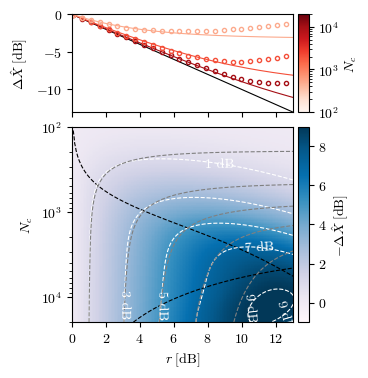

In [4]:
fig = plt.figure(figsize=(4.0, 4.0))

gs = fig.add_gridspec(2, 2, width_ratios=[3, 1], height_ratios=[1.5, 3], hspace=0.1, wspace=0.1)

ax_main = fig.add_subplot(gs[1, 0])
ax_top = fig.add_subplot(gs[0, 0])

ind_N = [130,85,45] # Cuts shown in the top axis (N_c ≈ 10000, 2000, 500)

# Main axis: map of -ΔX

nrm = mpl.colors.Normalize(-1,9)

cbar = plt.colorbar(cm.ScalarMappable(norm=nrm, cmap=cm.PuBu), cax = ax_main.inset_axes([1.02, 0.00, 0.05, 1.00]), orientation="vertical", location='right')
cbar.set_label(r'$-\Delta\hat{X}\;\text{[dB]}$', labelpad=3)

ax_main.pcolormesh(X, Y, db_full, cmap=cm.PuBu, norm=nrm, rasterized=True)
ax_main.contour(X, Y, cond_r, levels=[1], colors='black', linestyles = "dashed", linewidths = 0.8)
ax_main.contour(X, Y, cond_g0, levels=[1], colors='black', linestyles = "dashed", linewidths = 0.8)
ax_main.contour(X, Y, cond_chi, levels=[1], colors='black', linestyles = "dashed", linewidths = 0.8)
cs = ax_main.contour(X, Y, db_full, levels=[1,3,5,7,9], colors='white', linestyles = "dashed", linewidths = 0.8)
ax_main.contour(X, Y, db_eff, levels=[1,3,5,7,9], colors='grey', linestyles = "dashed", linewidths = 0.8)
plt.clabel(cs, fmt="%.0f dB", inline = False)
ax_main.set_ylabel(r'$N_c$')
ax_main.set_xlabel(r'$r\;\text{[dB]}$')
ax_main.set_yscale('log')
ax_main.set_xlim([r_dB.min(),r_dB.max()])
ax_main.set_ylim([N.max(),N.min()])
ax_main.set_xticks([0,2,4,6,8,10,12])

# Top axis: cuts at fixed N_c

cmap2 = plt.get_cmap('Reds')
nrm2 = mpl.colors.LogNorm(100,20000)

ax_top.plot(r_dB,-r_dB, color="black", linewidth=0.8) # Maximum squeezing

for i in range(3):
    ax_top.plot(r_dB,-db_eff[ind_N[i],:], color=cmap2(nrm2(N[ind_N[i]])), linewidth=0.8)
    ax_top.plot(r_dB,-db_full[ind_N[i],:], '.', fillstyle='none', markeredgewidth=1, color=cmap2(nrm2(N[ind_N[i]])), markevery=6, markersize=6)

cbar_2 = plt.colorbar(cm.ScalarMappable(norm=nrm2, cmap=cmap2), cax = ax_top.inset_axes([1.02, 0.00, 0.05, 1.00]), orientation="vertical", location='right')
cbar_2.set_label(r'$N_c$', labelpad=3)

ax_top.set_ylabel(r'$\Delta\hat{X}\;\text{[dB]}$')
ax_top.set_ylim([-13,0])
ax_top.set_xlim([r_dB.min(),r_dB.max()])
ax_top.set_xticks([0,2,4,6,8,10,12])
ax_top.tick_params(axis='x',labelbottom=False)

plt.savefig("figures/panel_a.svg", bbox_inches="tight")
plt.show()

## Panel (c): squeezing spectrum

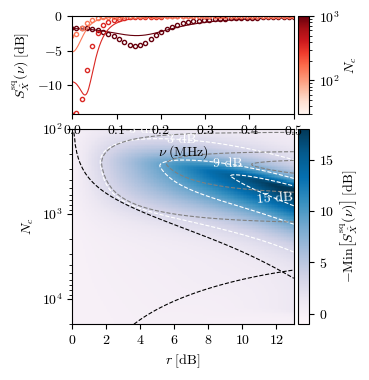

In [5]:
fig = plt.figure(figsize=(4.0, 4.0))

gs = fig.add_gridspec(2, 2, width_ratios=[3, 1], height_ratios=[1.5, 3], hspace=0.1, wspace=0.1)

ax_main = fig.add_subplot(gs[1, 0])
ax_top = fig.add_subplot(gs[0, 0])

ind_N = [70,35,11] # Cuts shown in the top axis (N_c ≈ 1200, 350, 150)

# Main axis: map of -Min[S(ν)]

nrm = mpl.colors.Normalize(-1,18)

cbar = plt.colorbar(cm.ScalarMappable(norm=nrm, cmap=cm.PuBu), cax = ax_main.inset_axes([1.02, 0.00, 0.05, 1.00]), orientation="vertical", location='right')
cbar.set_label(r'$-\text{Min}\left[S_{\hat X}^\text{sq}(\nu)\right]\;\text{[dB]}$', labelpad=3)

ax_main.pcolormesh(X, Y, Ssq_min_full, cmap=cm.PuBu, norm=nrm, rasterized=True)
ax_main.contour(X, Y, cond_r, levels=[1], colors='black', linestyles = "dashed", linewidths = 0.8)
ax_main.contour(X, Y, cond_g0, levels=[1], colors='black', linestyles = "dashed", linewidths = 0.8)
ax_main.contour(X, Y, cond_chi, levels=[1], colors='black', linestyles = "dashed", linewidths = 0.8)
cs = ax_main.contour(X, Y, Ssq_min_full, levels=[3,9,15], colors='white', linestyles = "dashed", linewidths = 0.8)
ax_main.contour(X, Y, Ssq_min_eff, levels=[3,9,15], colors='grey', linestyles = "dashed", linewidths = 0.8)
plt.clabel(cs, fmt="%.0f dB", inline = False)
ax_main.set_ylabel(r'$N_c$')
ax_main.set_xlabel(r'$r\;\text{[dB]}$')
ax_main.set_yscale('log')
ax_main.set_xlim([r_dB.min(),r_dB.max()])
ax_main.set_ylim([N.max(),N.min()])
ax_main.set_xticks([0,2,4,6,8,10,12])

# Top axis: spectrum at r ≈ 8.7 dB for three values of N_c

cmap2 = plt.get_cmap('Reds')
nrm2 = mpl.colors.LogNorm(30,1000)

for i in range(3):
    ax_top.plot(freqs,-Ssq_cut_full[:,ind_N[i]], '.', fillstyle='none', markeredgewidth=1, color=cmap2(nrm2(N[ind_N[i]])), markevery=6, markersize=6)
    ax_top.plot(freqs,-Ssq_cut_eff[:,ind_N[i]], color=cmap2(nrm2(N[ind_N[i]])), linewidth=0.8)

cbar_2 = plt.colorbar(cm.ScalarMappable(norm=nrm2, cmap=cmap2), cax = ax_top.inset_axes([1.02, 0.00, 0.05, 1.00]), orientation="vertical", location='right')
cbar_2.set_label(r'$N_c$', labelpad=3)

ax_top.set_ylabel(r'$S_{\hat X}^\text{sq}(\nu)\ \text{[dB]}$')
ax_top.set_xlabel(r'$\nu\;(\text{MHz})$')
ax_top.set_ylim([-Ssq_cut_full.max(),0])
ax_top.set_xlim([0,0.5])

plt.savefig("figures/panel_c.svg", bbox_inches="tight")
plt.show()